# WP08 — B0/B1/B2 ilk deney fazının kapanışı

Kullanıcı B0/B1/B2 sonuçlarını ve ilk fazın bu modellerle kapanmasını kabul etti. ATC, Random Forest, kimya MLP ve protein-mean MLP **yapılmadı; ilk faz dışında ertelendi**. ROADMAP ve eski deneyler korunur. Bu notebook yalnız mevcut sonuçları okur; model fit, yeni tahmin, hiperparametre araması veya WP09 encoder içermez.

**Görev SIDER'da gözlenen kayıtları yeni ilaçlar için sıralamak. Unknown gerçek negatif değildir; klinik yan etki olasılığı, nedensellik veya hasta güvenliği doğrulaması yapılmadı.** B0 ilk B1/B2 sonuçları görüldükten sonra eklenen keşifsel referanstır. Sonuç kaynakları, QA dizinleri ve hash'ler aşağıda açıkça gösterilir.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').is_file():
    if ROOT.parent == ROOT: raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
QA=ROOT/'reports/qa/WP08/final_closure_v1'
B0=ROOT/'reports/qa/WP08/B0_frequency_reference_v1'
FIG=ROOT/'reports/figures/WP08/final_closure_v1';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_columns',18);pd.set_option('display.max_colwidth',100)
metrics=pd.read_csv(QA/'accepted_paired_metrics.csv')
delta=pd.read_csv(QA/'accepted_paired_differences.csv')
audit=json.loads((QA/'integrity_audit.json').read_text(encoding='utf-8'))
contract=json.loads((QA/'WP09_comparison_contract_draft.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'ilk_faz':'KAPANDI: B0/B1/B2','baseline_sürümü':audit['old_models']['version'],
                      'B0_sürümü':audit['B0']['version'],'seed':audit['seed'],
                      'ilaç':audit['source_PT']['drugs'],'kaynak_PT':audit['source_PT']['PT_CUI'],
                      'kaynak_pozitif_çift':audit['source_PT']['positive_pairs'],
                      'WP09_eğitim_onayı':contract['WP09_training_authorized']}]))
display(pd.read_csv(QA/'scope_disposition.csv'))

,ilk_faz,baseline_sürümü,B0_sürümü,seed,ilaç,kaynak_PT,kaynak_pozitif_çift,WP09_eğitim_onayı
0,KAPANDI: B0/B1/B2,WP08-observed-record-L2LR-v1,B0_frequency_reference_v1,20261106,62,1061,6416,False


,task,status,explanation
0,B0 train-frequency reference,COMPLETED_ACCEPTED,Sonuç sonrası keşifsel; sabit v1 skorları
1,B1 5 kimya + maske L2-LR,COMPLETED_ACCEPTED,Mevcut seçilmiş C ve sonuçlar aynen
2,B2 kimya + 4 rol protein özeti + maskeler L2-LR,COMPLETED_ACCEPTED,61 input kapsamı; ortak54 drug-AP üstünlüğü yok
3,Drug-disjoint split / train-only dönüşüm / train PT sözlüğü,COMPLETED_ACCEPTED,v1 kilidi; outer5/inner3 ve ayrı stres
4,"AP/AUROC, NA, coverage, koşullu grup bootstrap ve sızıntı testleri",COMPLETED_ACCEPTED,Gerçek-negatif/klinik doğrulama değildir
5,ATC varyantı,DEFERRED_OUTSIDE_PHASE1,"ROADMAPta korunur; yapılmadı, tamamlandı sayılmaz"
6,Random Forest,DEFERRED_OUTSIDE_PHASE1,ROADMAPta korunur; sonuç sonrası arama yapılmadı
7,Kimya MLP,DEFERRED_OUTSIDE_PHASE1,ROADMAPta korunur; yapılmadı
8,Protein-mean MLP,DEFERRED_OUTSIDE_PHASE1,B2 LR bunun yerine geçmiş sayılmaz; yapılmadı
9,Gerçek PU loss / kaynak seçim önseli modeli,NOT_IMPLEMENTED_NOT_CLAIMED,Mevcut çalışma observed-record proxy; ek yöntem ayrı kapsam kararı


**Yorum:** B1/B2 için model sürümü değişmedi. Kapanış kapsam kararı, yapılmamış roadmap varyantlarını tamamlanmış yapmaz. B0'ın girdisiz nüfus referansı verebilmesi Methenamine'in B1/B2 abstention'ını kaldırmaz.

## 1. Aynı 54 ilaç ve aynı PT anahtarlarında karşılaştırma

,protocol,model,estimate,CI95_low,CI95_high,valid_bootstrap_replicates
0,primary,B1,0.655642,0.613111,0.692041,1000
5,primary,B2,0.626239,0.579200,0.670094,1000
10,primary,B0_all_train,0.646507,0.603990,0.685192,1000
15,primary,B0_like_B1,0.643787,0.602130,0.681983,1000
20,primary,B0_like_B2,0.646604,0.604371,0.685339,1000
25,stress,B1,0.631871,0.570003,0.686266,1000
30,stress,B2,0.599696,0.534057,0.657665,1000
35,stress,B0_all_train,0.647157,0.604955,0.687391,1000
40,stress,B0_like_B1,0.643993,0.602932,0.684432,1000
45,stress,B0_like_B2,0.646561,0.604518,0.687085,1000


,protocol,first,reference,first_minus_reference,CI95_low,CI95_high
0,primary,B1,B0_like_B1,0.011855,-0.002096,0.027365
10,primary,B2,B0_like_B2,-0.020365,-0.043756,0.003183
20,primary,B2,B1,-0.029403,-0.051084,-0.009335
25,stress,B1,B0_like_B1,-0.012122,-0.041223,0.011061
35,stress,B2,B0_like_B2,-0.046864,-0.076893,-0.017625
45,stress,B2,B1,-0.032174,-0.056857,-0.009645


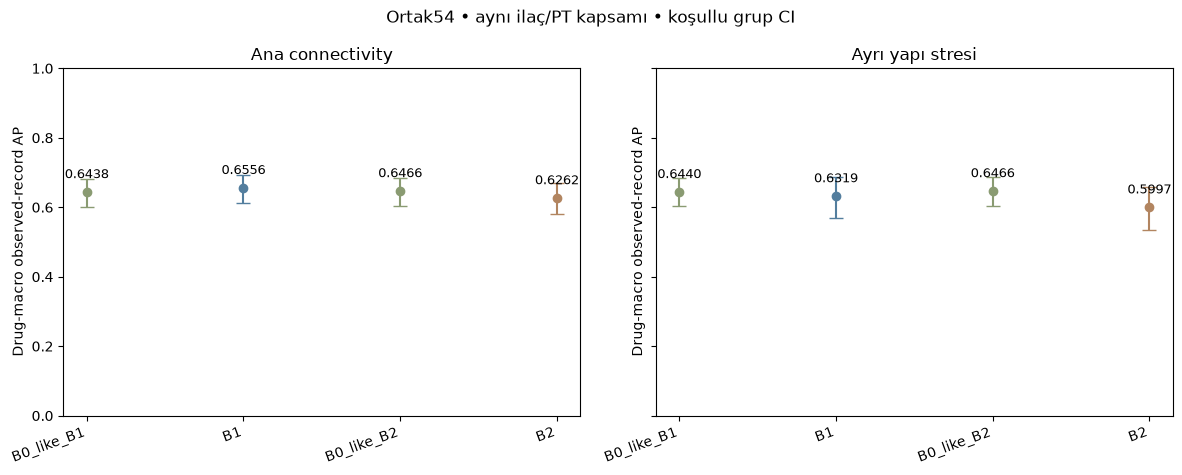

In [2]:
ap=metrics[metrics.metric.eq('drug_macro_AP')]
display(ap[['protocol','model','estimate','CI95_low','CI95_high','valid_bootstrap_replicates']])
selected=delta[delta.metric.eq('drug_macro_AP') & ((delta['first'].eq('B1') & delta.reference.eq('B0_like_B1')) | (delta['first'].eq('B2') & delta.reference.isin(['B0_like_B2','B1'])))]
display(selected[['protocol','first','reference','first_minus_reference','CI95_low','CI95_high']])
order=['B0_like_B1','B1','B0_like_B2','B2'];colors=['#8a9b72','#537e9e','#8a9b72','#b28560']
fig,axs=plt.subplots(1,2,figsize=(12,4.8),sharey=True)
for ax,protocol,title in zip(axs,['primary','stress'],['Ana connectivity','Ayrı yapı stresi']):
    sub=ap[ap.protocol.eq(protocol)].set_index('model').loc[order]
    for i,(model,row) in enumerate(sub.iterrows()):
        ax.errorbar(i,row.estimate,yerr=[[row.estimate-row.CI95_low],[row.CI95_high-row.estimate]],fmt='o',color=colors[i],capsize=5)
        ax.annotate(f'{row.estimate:.4f}',(i,row.estimate),xytext=(0,10),textcoords='offset points',ha='center',fontsize=9)
    ax.set_xticks(range(4),order,rotation=20,ha='right');ax.set(title=title,ylim=(0,1),ylabel='Drug-macro observed-record AP')
fig.suptitle('Ortak54 • aynı ilaç/PT kapsamı • koşullu grup CI',fontsize=12)
plt.tight_layout();plt.savefig(FIG/'01_accepted_paired_AP.png',dpi=160);plt.show()

**Yorum:** Ana B1=0,6556 ile eşleşen B0=0,6438 arasındaki +0,0119 farkın CI'ı sıfırı içerir; ek başarı henüz belirgin değildir. B2=0,6262, kendi B0=0,6466 referansını geçmedi; stres farkı da düşük kaldı. Bu koşullu CI'lar bağımsız dış doğrulama değildir.

B2'nin 61 ilaçta input bulması kapsam kazancıdır; ortak54'te performans artışı değildir. Küçük örneklemde 234 giriş alanı, rol ortalamasının bilgi kaybı ve farklı biyolojik/kayıt mekanizmaları **olası açıklamalar**dır; bunları neden diye kanıtlayan yeni deney yapılmadı. B0/B1 AP oranı açıklanan nedensel yüzde olarak hesaplanmaz.

## 2. Aynı PT'de ilaçları sıralamak ile aynı ilaçta PT'leri sıralamak

,model,estimate,descriptive_mean_of_5_fold_class_AUROC
0,B1,0.481439,0.551275
1,B2,0.543061,0.571560
2,B0_all_train,0.328927,0.500000
3,B0_like_B1,0.318814,0.500000
4,B0_like_B2,0.328135,0.500000


,protocol,model,descriptive_mean_of_5_fold_class_AUROC,CI_status
0,primary,B0_all_train,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
1,primary,B0_like_B1,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
2,primary,B0_like_B2,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
3,primary,B1,0.551275,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
4,primary,B2,0.571560,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
5,stress,B0_all_train,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
6,stress,B0_like_B1,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
7,stress,B0_like_B2,0.500000,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
8,stress,B1,0.572165,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement
9,stress,B2,0.562478,Descriptive diagnostic only; folds not independent; no t-CI or metric replacement


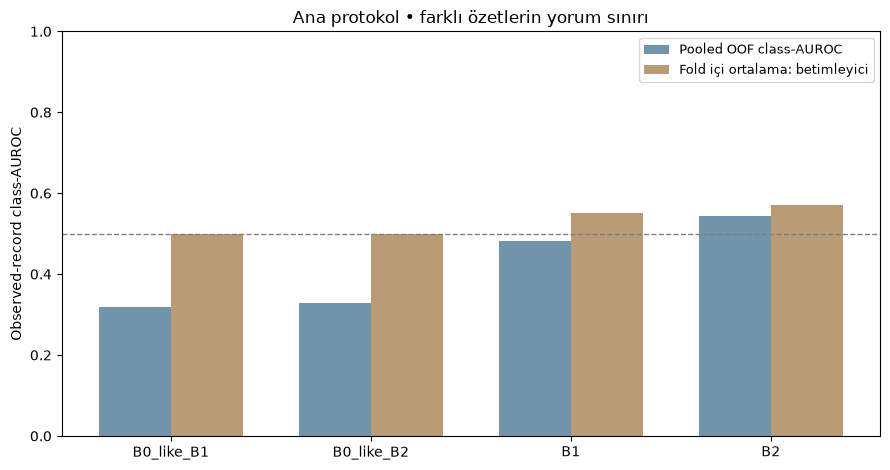

In [3]:
diag=pd.read_csv(B0/'within_fold_AUROC_descriptive_mean.csv')
pooled=metrics[metrics.protocol.eq('primary')&metrics.metric.eq('class_macro_AUROC')][['model','estimate']]
comparison=pooled.merge(diag[diag.protocol.eq('primary')][['model','descriptive_mean_of_5_fold_class_AUROC']],on='model')
display(comparison);display(diag[['protocol','model','descriptive_mean_of_5_fold_class_AUROC','CI_status']])
order=['B0_like_B1','B0_like_B2','B1','B2'];p=comparison.set_index('model').loc[order]
fig,ax=plt.subplots(figsize=(9,4.8));x=np.arange(4)
ax.bar(x-.18,p.estimate,.36,label='Pooled OOF class-AUROC',color='#7295ac')
ax.bar(x+.18,p.descriptive_mean_of_5_fold_class_AUROC,.36,label='Fold içi ortalama: betimleyici',color='#b99c76')
ax.axhline(.5,color='gray',ls='--',lw=1);ax.set_xticks(x,order);ax.set(ylim=(0,1),ylabel='Observed-record class-AUROC',title='Ana protokol • farklı özetlerin yorum sınırı');ax.legend(fontsize=9)
plt.tight_layout();plt.savefig(FIG/'02_AUROC_interpretation.png',dpi=160);plt.show()

**Yorum:** Drug-AP ilaç içinde PT sıralaması; class-AUROC aynı PT için ilaç sıralamasıdır. B2'nin pooled class-AUROC artışı birincil drug-AP kaybını telafi eden genel üstünlük değildir. B0 fold/PT içinde sabit skor verdiğinden tanımlı AUROC=0,5'tir. Pooled sonuçtaki yaklaşık0,32, farklı fold train frekanslarının/skor ölçeklerinin ve değişen sözlüklerin birleşmesinden etkilenir. B0 ters biyolojik tahmin yapıyor sonucu çıkarılmaz. Foldlar bağımsız tekrar değildir; betimleyici ortalamaya t-CI veya yeni seçim uygulanmadı.

## 3. Kaynak PT uzayı, unknown ve kapsam dışı pozitifler

,protocol,scope,model,exploratory_after_baseline,inventory_drugs,scored_drugs,drug_AP_evaluable,scored_pairs,observed_positive_scored,unknown_scored_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,class_AUROC_evaluable
1,primary,own_B1,B0_all_train,True,62,54,54,13964,3820,10144,5505,1685,256
4,primary,own_B2,B0_all_train,True,62,61,61,18004,4576,13428,6405,1829,293
8,primary,paired54,B0_all_train,True,62,54,54,13964,3820,10144,5505,1685,256
13,primary,complete_case53,B0_all_train,True,62,53,53,13694,3730,9964,5347,1617,256
16,primary,B0_all62_reference_ONLY,B0_all_train,True,62,62,62,18334,4596,13738,6416,1820,294


,ortak_ilaç,skorlanan_çift,pozitif,unknown_gerçek_negatif_değil,bu_ilaçlarda_kaynak_pozitif,skor_sözlüğü_dışında_pozitif,tüm62_kaynak_PT
0,54,13964,3820,10144,5505,1685,1061


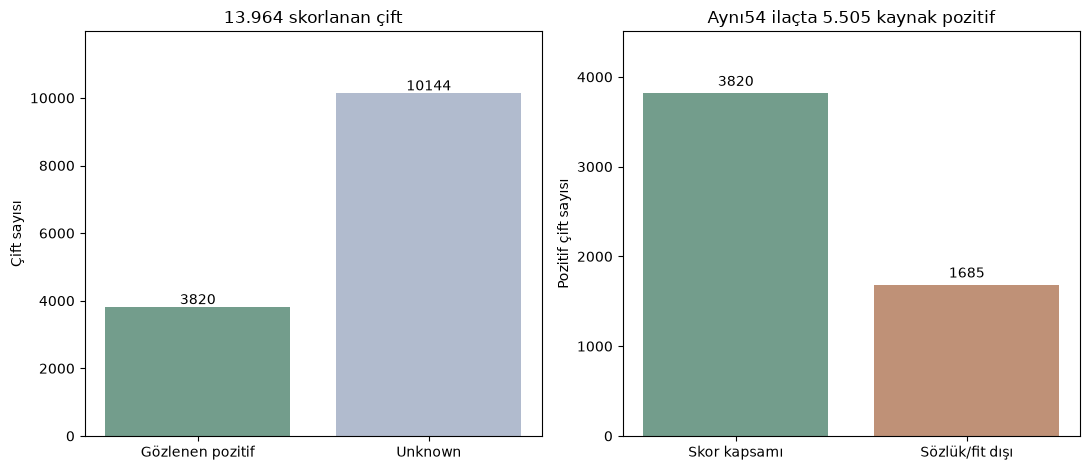

In [4]:
coverage=pd.read_csv(QA/'accepted_primary_coverage.csv')
display(coverage[coverage.model.eq('B0_all_train')].drop(columns=['semantics']))
c=coverage[coverage.scope.eq('paired54') & coverage.model.eq('B0_all_train')].iloc[0]
display(pd.DataFrame([{'ortak_ilaç':c.scored_drugs,'skorlanan_çift':c.scored_pairs,
    'pozitif':c.observed_positive_scored,'unknown_gerçek_negatif_değil':c.unknown_scored_NOT_verified_negative,
    'bu_ilaçlarda_kaynak_pozitif':c.source_positive_for_scored_drugs,
    'skor_sözlüğü_dışında_pozitif':c.out_of_scored_vocab_positive,'tüm62_kaynak_PT':1061}]))
fig,axs=plt.subplots(1,2,figsize=(11,4.8))
axs[0].bar(['Gözlenen pozitif','Unknown'],[c.observed_positive_scored,c.unknown_scored_NOT_verified_negative],color=['#739d8c','#b1bbce'])
axs[0].set(title='13.964 skorlanan çift',ylabel='Çift sayısı')
axs[1].bar(['Skor kapsamı','Sözlük/fit dışı'],[c.observed_positive_scored,c.out_of_scored_vocab_positive],color=['#739d8c','#bf9177'])
axs[1].set(title='Aynı54 ilaçta 5.505 kaynak pozitif',ylabel='Pozitif çift sayısı')
for ax in axs:
    for bar in ax.patches:ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+80,str(int(bar.get_height())),ha='center')
    ax.margins(y=.18)
plt.tight_layout();plt.savefig(FIG/'03_target_coverage_limits.png',dpi=160);plt.show()

**Yorum:** 1.685 kapsam dışı kaynak pozitif, ortak54'ün folda özgü skorlanmayan pozitifleridir; bütün62 için eksik/yanlış-negatif sayısı değildir. Skorlanmayan PT'ler ve NA sınıflar sıfır başarıya çevrilmedi. Kaynak evren 1.061 PT iken pooled ortak kapsam306 CUI, class metriği tanımlı256/NA50'dir. Tüm1.061 PT uzayında performans iddiası kurulamaz. Unknown, kesin negatif veya biyolojik yokluk değildir. İki grafiğin paydaları farklıdır ve açık gösterilmiştir.

## 4. WP09 için plan: onay kapısı

In [5]:
topology=pd.read_csv(QA/'WP09_train_only_topology_preflight.csv')
summary=topology.groupby(['protocol','threshold']).agg(train_human_min=('strict_human_train_nodes','min'),train_human_max=('strict_human_train_nodes','max'),pairs_min=('undirected_PPI_pairs','min'),pairs_max=('undirected_PPI_pairs','max'),isolates_max=('isolated_human_nodes','max')).reset_index()
display(summary)
display(pd.DataFrame([{'sözleşme_sürümü':contract['version'],'WP09_uygulama_onayı':contract['WP09_implementation_authorized'],
    'WP09_eğitim_onayı':contract['WP09_training_authorized'],'eşik':contract['graph']['threshold'],
    'K12_kenarı_insan_ağında':contract['graph']['K12_MG1655_23_conditional_edges_in_human_graph'],
    'context80':contract['graph']['context80'],'sonuç_sonrası_keşifsel':contract['exploratory_after_seen_baselines']}]))
display(pd.DataFrame({'zorunlu_ablation':contract['ablations']}))
display(pd.DataFrame({'uygulama_öncesi_onay_konuları':contract['open_approval_items']}))

,protocol,threshold,train_human_min,train_human_max,pairs_min,pairs_max,isolates_max
0,primary,400,37,59,225,559,2
1,primary,700,37,59,70,178,11
2,primary,900,37,59,20,78,26
3,stress,400,35,61,254,564,2
4,stress,700,35,61,90,176,12
5,stress,900,35,61,32,76,28


,sözleşme_sürümü,WP09_uygulama_onayı,WP09_eğitim_onayı,eşik,K12_kenarı_insan_ağında,context80,sonuç_sonrası_keşifsel
0,WP09-comparison-contract-draft-v1,False,False,None,False,False,True


,zorunlu_ablation
0,same_architecture_noPPI
1,same_architecture_real_strict_human_PPI
2,same_architecture_degree_preserving_shuffled_human_PPI


,uygulama_öncesi_onay_konuları
0,protein universe and query policy
1,PPI threshold policy
2,capacity/loss/optimizer/epoch/early-stop
3,inner selection/tie/NA policy
4,init seed schedule
5,shuffle swaps/min-change/null repeats


**Yorum:** Bu tablo mevcut küçük WP06 kaynak tablosundan yalnız train protein evreninin topolojik ön kontrolüdür; eğitim grafı oluşturulmadı. 63 kesin insan düğümünün tamamı her foldta bulunmaz; eşik400/700/900 henüz seçilmedi. İzole/PPI'sız proteinler silinmez; 23 koşullu K12/MG1655 kenarı insan ağına eklenmez; özellik eksik80 context yoktur.

Plan, aynı mimaride noPPI/realPPI/shuffledPPI, ayırt edici forward ve gradient testleri, aynı frozen split/PT/input kapsamı gerektirir. Bunlar **henüz uygulanmış testler değildir**. Model kapasitesi/optimizer/early-stop/null politikası ve uygulama onayı açık kalır. Daha önce görülen outer sonuçlar WP09'da seçim için kullanılamaz; aynı veride gelecekteki kıyas keşifseldir.

## 5. Kapanış denetimi

In [6]:
tests=pd.read_csv(QA/'existing_test_suite_results.csv')
display(tests[['suite','tests','unittest_seconds','passed','persistent_model_or_score_writes']])
display(pd.DataFrame([{'mevcut_test_sayısı':int(tests.tests.sum()),'tümü_geçti':bool(tests.passed.all()),
    'korunan_dosya':audit['accepted_artifacts']['files_checked'],'değişen_dosya':len(audit['accepted_artifacts']['changed']),
    'ham_içerik_tekrar_taraması':audit['raw_content_rescan_or_hash'],
    'WP09_eğitim_onayı':audit['WP09_training_authorized']}]))
display(pd.DataFrame(audit['raw_metadata_only']))
display(pd.DataFrame([{'split_file':k,'SHA256':v} for k,v in audit['frozen_split_manifest'].items()]))

,suite,tests,unittest_seconds,passed,persistent_model_or_score_writes
0,test_wp08.py,28,15.266,True,False
1,test_wp08_prepare.py,28,14.387,True,False
2,test_wp08_baseline.py,28,7.188,True,False
3,test_wp08_b0.py,19,4.780,True,False


,mevcut_test_sayısı,tümü_geçti,korunan_dosya,değişen_dosya,ham_içerik_tekrar_taraması,WP09_eğitim_onayı
0,103,True,1369,0,False,False


,file,exists,same_size_and_mtime
0,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.aliase...,True,True
1,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Escherichia coli\511145.protein....,True,True
2,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.links....,True,True
3,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Homo Sapiens\9606.protein.links....,True,True
4,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Escherichia coli\511145.protein....,True,True
5,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\string-db\Escherichia coli\511145.protein....,True,True
6,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\DrugBank\drugbank_all_full_database.xml\fu...,True,True
7,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\Dataset\SIDER\meddra_all_se.tsv\meddra_all_se.tsv,True,True


,split_file,SHA256
0,split_lock_v1.json,cda71983763b8e1cbbca055400f6cb4ed4692cbbec016abf36a101337335faea
1,outer_membership_v1.csv,079557dc2b9e27ecd1064cf78a130de6f988865f0964d548709ab299cdd51e89
2,nested_partitions_v1.csv,33528de50c4420be89713a8e648debb06177d3ddafe897955075df8a41a234e5


**Yorum:** Mevcut103 test yeniden geçti; eski test logları, modeller, skorlar ve QC kararları korunur. Baseline unit testleri yalnız RAM'de küçük fit/mutasyon/tekrar üretim kontrolleri yapar; yeni deney modeli yazmaz. Ham büyük kaynaklarda sadece boyut/mtime kontrolü yapıldı, tam içerik hash doğrulaması tekrarlanmadı.

Sonuçlar kaynak kayıt sıralamasına özgüdür. Koşullu grup CI, bütün yeniden eğitim belirsizliği veya bağımsız dış doğrulama değildir. Klinik olasılık, nedensellik ve hasta güvenliği sonucu çıkarılmaz.

[Kapanış raporu](../reports/WP08_FINAL_CONCLUSIONS.md) ve [WP09 taslak sözleşmesi](../docs/plan/WP09_COMPARISON_CONTRACT_DRAFT.md) ayrıntıları içerir. **WP08 ilk faz kapandı; WP09 uygulaması kullanıcı onayını bekliyor.**